# Figures for the F1 mini project

Six figures, one per figure in the report, in the order the report uses them.

| Cell | Figure | Report section |
|---|---|---|
| 1 | Setup, run this first | |
| 2 | Fig 1 - race-lap coverage and the split | Data description |
| 3 | Fig 2 - random split against time split | Preprocessing and evaluation |
| 4 | Fig 3 - pit-stop detection, PR-AUC | Evaluation with imbalanced classes |
| 5 | Fig 4 - qualifying order, walk-forward | Qualifying order |
| 6 | Fig 5 - race winners, walk-forward | Race order and points |
| 7 | Fig 6 - lap-time consistency by compound | Lap-time consistency |
| 8 | Audit, prints every number the figures used | |

Every number is read from the files the model notebook saved. Nothing is typed
in by hand, so a figure cannot drift away from the code that produced it.

Run the model notebook first. These cells read its outputs; they do not refit
anything, so the whole thing takes a few seconds.

PNGs are written to `figures/` at 300 dpi.


In [1]:
# ============================================================
# FIGURES - SETUP (run this cell first)
#
# Builds the six figures used in the report. Every number is read
# from the files the model notebook saved, so a figure can never
# drift away from the code that produced it.
#
# Works whether the files sit loose in the working folder or inside
# the tidied submission folders: find() looks in both.
# ============================================================
import os, json, glob, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# --- find the project folder -------------------------------------
# Tries the usual working folder; if that is not there, starts from wherever
# this notebook is and walks up until the project files come into view. That
# way it runs both from the working folder and from inside the tidied
# submission folder.
BASE = os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop", "Yug", "Sem 5", "ML", "Grp assignment")
if os.path.isdir(BASE):
    os.chdir(BASE)
else:
    for _ in range(4):
        if glob.glob(os.path.join("**", "model_pace.parquet"), recursive=True):
            break
        if os.path.dirname(os.getcwd()) == os.getcwd():
            break
        os.chdir("..")
print("project folder:", os.getcwd())
FIGDIR = "7_figures" if os.path.isdir("7_figures") else "figures"
os.makedirs(FIGDIR, exist_ok=True)


def find(name):
    """Return the path to a file, wherever it sits under the project folder."""
    if os.path.exists(name):
        return name
    hits = glob.glob(os.path.join("**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found anywhere under {os.getcwd()}")
    return sorted(hits, key=len)[0]


# ---------- one look for every figure ----------
RED, DARK, GREY, LIGHT = "#E10600", "#15151E", "#8A8A93", "#D9D9DE"
BLUE = "#2E86DE"
C_COLORS = {1: "#7A7A85", 2: "#2E86DE", 3: "#F5C518", 4: "#F28C28", 5: "#E10600"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.labelcolor": DARK, "axes.edgecolor": GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": LIGHT, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": DARK, "ytick.color": DARK, "legend.frameon": False,
})

CHECK = []          # collects every number a figure prints, for the audit cell at the end


def save(fig, name, note=None):
    if note:
        fig.canvas.draw()
        y = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight() - 0.015
        fig.text(0.01, y, note, fontsize=8.5, color=GREY, ha="left", va="top")
    fig.savefig(os.path.join(FIGDIR, name + ".png"))
    print("saved:", os.path.join(FIGDIR, name + ".png"))
    plt.show()


def label(ax, bars, vals, fmt="{:.2f}", pad=0.012, size=10.5):
    span = max(vals) - min(0, min(vals)) or 1
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (pad * span if v >= 0 else -pad * span),
                fmt.format(v), ha="center", va="bottom" if v >= 0 else "top",
                fontsize=size, fontweight="bold", color=DARK)


# ---------- load what the model notebook produced ----------
R3 = pd.read_csv(find("results_model3.csv"))
R5v2 = pd.read_csv(find("results_model5_v2.csv"), index_col=0)
R6v2 = pd.read_csv(find("results_model6_v2.csv"), index_col=0)
m1meta = json.load(open(find("model1_pace.json")))
m3meta = json.load(open(find("model3_pit.json")))
pace = pd.read_parquet(find("model_pace.parquet"))
laps = pd.read_excel(find("F1_2026_races.xlsx"), sheet_name="Laps")
events = laps.groupby("Round")["EventName"].first().str.replace(" Grand Prix", "")
print(f"loaded: {len(laps):,} race laps over {laps.Round.nunique()} rounds, "
      f"{len(pace):,} modelling laps, results for models 3, 5 and 6")

project folder: C:\Users\bhogi\OneDrive\Desktop\Yug\Sem 5\ML\Grp assignment
loaded: 23,323 race laps over 20 rounds, 17,758 modelling laps, results for models 3, 5 and 6


saved: figures\fig1_data_coverage.png


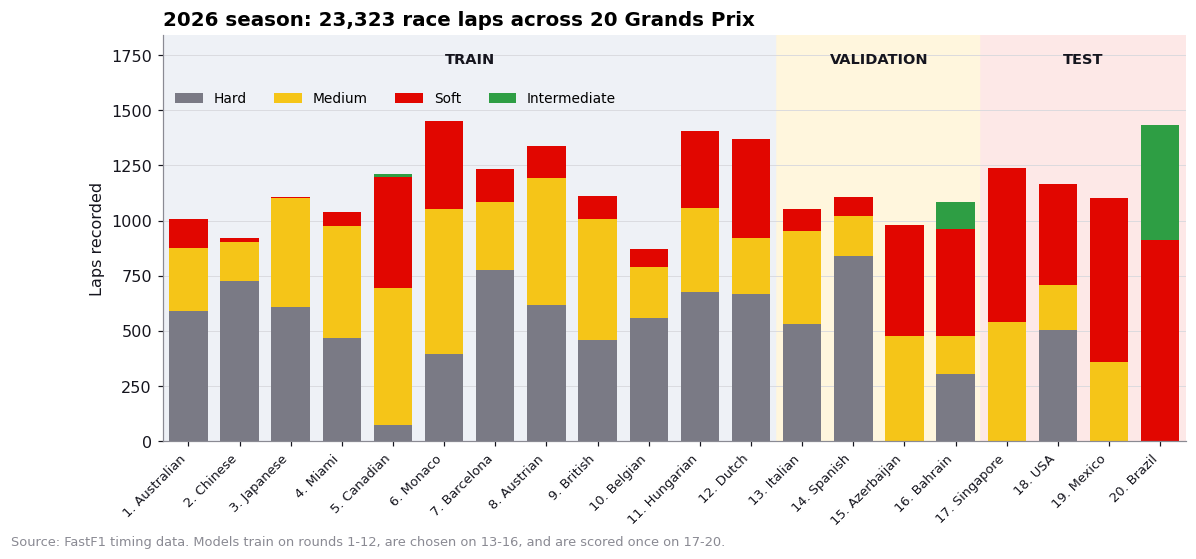

In [2]:
# ============================================================
# FIGURE 1 - THE DATA: laps per race, by tyre, with the split
# Report section: Data description
# ============================================================
cnt = laps.pivot_table(index="Round", columns="Compound", values="LapNumber", aggfunc="count").fillna(0)
order = [c for c in ["HARD", "MEDIUM", "SOFT", "INTERMEDIATE", "WET"] if c in cnt.columns]
colors = {"HARD": "#7A7A85", "MEDIUM": "#F5C518", "SOFT": RED,
          "INTERMEDIATE": "#2E9E44", "WET": "#2E86DE"}

fig, ax = plt.subplots(figsize=(12, 4.8))
bottom = np.zeros(len(cnt))
for c in order:
    ax.bar(cnt.index, cnt[c], bottom=bottom, color=colors[c], label=c.title(), width=0.75)
    bottom += cnt[c].values
for lo, hi, lab, col in [(0.5, 12.5, "TRAIN", "#EEF1F6"),
                         (12.5, 16.5, "VALIDATION", "#FFF6DD"),
                         (16.5, 20.5, "TEST", "#FDE8E7")]:
    ax.axvspan(lo, hi, color=col, zorder=0)
    ax.text((lo + hi) / 2, bottom.max() * 1.18, lab, ha="center", fontsize=9.5,
            fontweight="bold", color=DARK)
short = events.replace({"United States": "USA", "Mexico City": "Mexico", "São Paulo": "Brazil"})
ax.set_xticks(cnt.index)
ax.set_xticklabels([f"{r}. {short[r]}" for r in cnt.index], rotation=45, ha="right", fontsize=8.5)
ax.set_xlim(0.5, 20.5)
ax.set_ylim(0, bottom.max() * 1.27)
ax.set_ylabel("Laps recorded")
ax.grid(axis="x", visible=False)
ax.set_title(f"2026 season: {len(laps):,} race laps across {laps.Round.nunique()} Grands Prix")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0.0, 0.89), fontsize=9)
save(fig, "fig1_data_coverage",
     "Source: FastF1 timing data. Models train on rounds 1-12, are chosen on 13-16, and are scored once on 17-20.")
CHECK.append(("Fig 1", "total race laps", f"{len(laps):,}"))
CHECK.append(("Fig 1", "rounds", laps.Round.nunique()))


# ============================================================
# FIGURE 2 - THE LEAKAGE CHECK
# Same model, same data, same features. Only the split changes.
# Report section: Preprocessing / Evaluation
# ============================================================

saved: figures\fig2_leakage_check.png


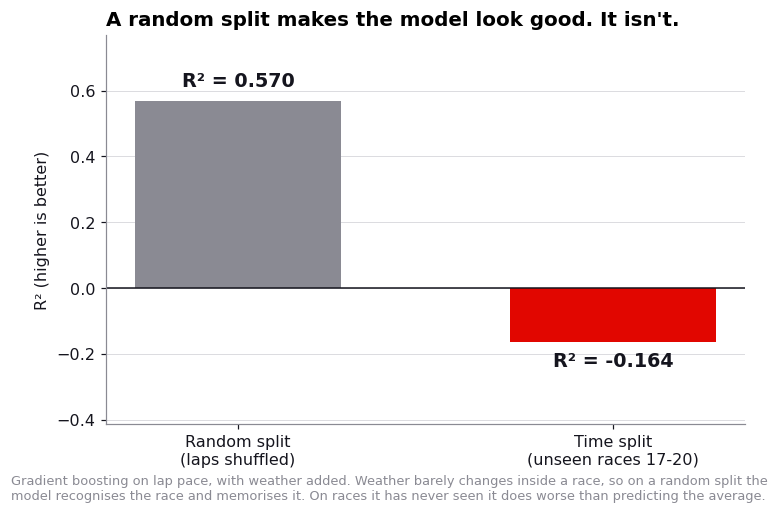

In [3]:
# ============================================================
# FIGURE 2 - THE LEAKAGE CHECK
# Same model, same data, same features. Only the split changes.
# Report section: Preprocessing / Evaluation
# ============================================================
lk = m1meta["leakage_check"]
vals = [lk["random split R2"], lk["time split R2"]]
labels = ["Random split\n(laps shuffled)", "Time split\n(unseen races 17-20)"]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
bars = ax.bar(labels, vals, color=[GREY, RED], width=0.55)
ax.axhline(0, color=DARK, lw=1)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + (0.03 if v >= 0 else -0.03), f"R² = {v:.3f}",
            ha="center", va="bottom" if v >= 0 else "top", fontsize=12.5, fontweight="bold", color=DARK)
ax.set_ylabel("R² (higher is better)")
ax.set_ylim(min(vals) - 0.25, max(vals) + 0.2)
ax.grid(axis="x", visible=False)
ax.set_title("A random split makes the model look good. It isn't.")
save(fig, "fig2_leakage_check",
     "Gradient boosting on lap pace, with weather added. Weather barely changes inside a race, so on a random split the\n"
     "model recognises the race and memorises it. On races it has never seen it does worse than predicting the average.")
CHECK.append(("Fig 2", "random split R2", round(vals[0], 3)))
CHECK.append(("Fig 2", "time split R2", round(vals[1], 3)))




saved: figures\fig3_pit_pr_auc.png


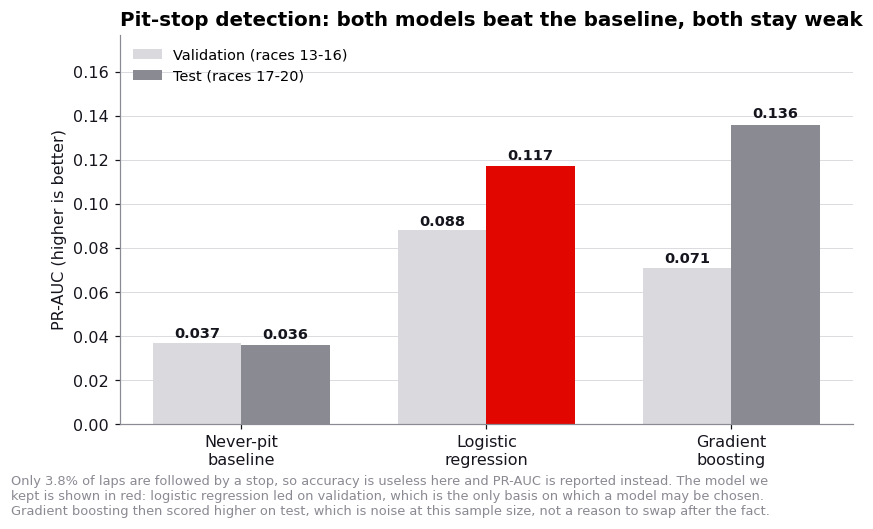

In [4]:
# ============================================================
# FIGURE 3 - PIT STOP DETECTION (Model 3)
# PR-AUC on validation (how the model was chosen) and on test.
# Report section: Evaluation (imbalanced classes)
# ============================================================
d = R3.set_index("Model")
names = ["A. Baseline (never pit)", "B. Logistic regression", "C. Gradient boosting"]
short = ["Never-pit\nbaseline", "Logistic\nregression", "Gradient\nboosting"]
val = [d.loc[n, "Val_PR_AUC"] for n in names]
test = [d.loc[n, "PR_AUC"] for n in names]
picked = m3meta["model"]
pick_i = names.index(picked)

x = np.arange(3)
w = 0.36
fig, ax = plt.subplots(figsize=(8.6, 4.6))
b1 = ax.bar(x - w / 2, val, w, color=LIGHT, label="Validation (races 13-16)")
b2 = ax.bar(x + w / 2, test, w, color=[RED if i == pick_i else GREY for i in range(3)],
            label="Test (races 17-20)")
label(ax, b1, val, "{:.3f}", size=9.5)
label(ax, b2, test, "{:.3f}", size=9.5)
ax.set_xticks(x)
ax.set_xticklabels(short)
ax.set_ylabel("PR-AUC (higher is better)")
ax.set_ylim(0, max(test + val) * 1.3)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=9.5)
ax.set_title("Pit-stop detection: both models beat the baseline, both stay weak")
save(fig, "fig3_pit_pr_auc",
     "Only 3.8% of laps are followed by a stop, so accuracy is useless here and PR-AUC is reported instead. The model we\n"
     "kept is shown in red: logistic regression led on validation, which is the only basis on which a model may be chosen.\n"
     "Gradient boosting then scored higher on test, which is noise at this sample size, not a reason to swap after the fact.")
for n, s, v, t in zip(names, short, val, test):
    CHECK.append(("Fig 3", f"{s.replace(chr(10), ' ')} PR-AUC val / test", f"{v:.3f} / {t:.3f}"))


# ============================================================
# FIGURE 4 - QUALIFYING, WALK-FORWARD (Model 5 v2)
# Does practice data improve the predicted grid order?
# Report section: Qualifying order
# ============================================================

saved: figures\fig4_qualifying_walkforward.png


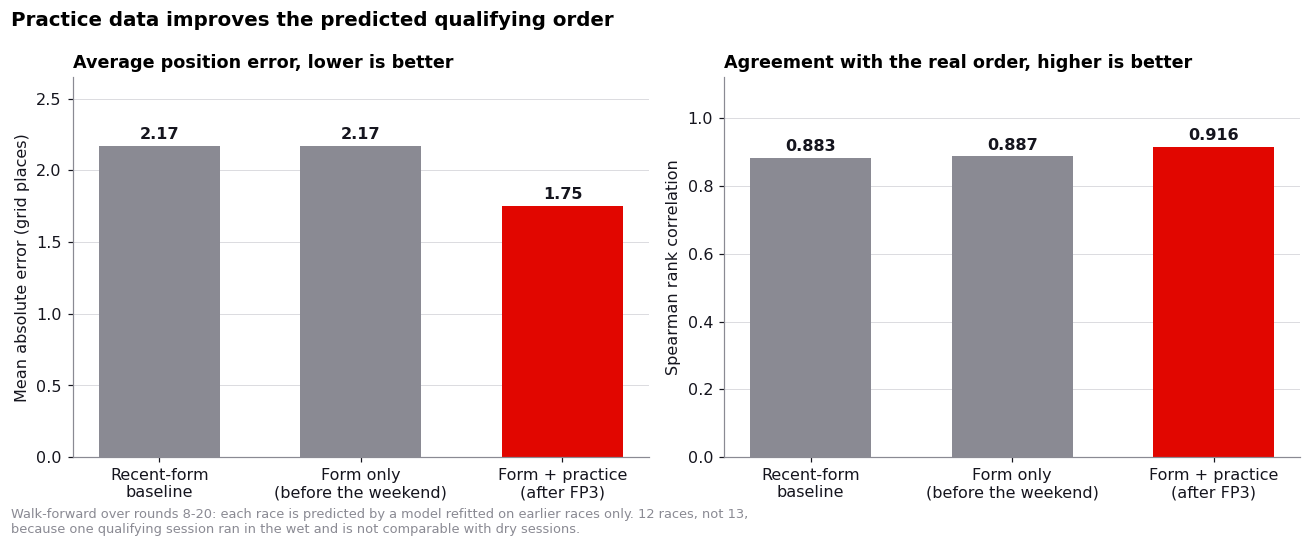

In [5]:
# ============================================================
# FIGURE 4 - QUALIFYING, WALK-FORWARD (Model 5 v2)
# Does practice data improve the predicted grid order?
# Report section: Qualifying order
# ============================================================
d = R5v2
short = ["Recent-form\nbaseline", "Form only\n(before the weekend)", "Form + practice\n(after FP3)"]
mae = d["MAE"].tolist()
rho = d["rho"].tolist()
best = int(np.argmin(mae))
cols = [RED if i == best else GREY for i in range(3)]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.7))
b1 = a1.bar(short, mae, color=cols, width=0.6)
label(a1, b1, mae, "{:.2f}")
a1.set_ylabel("Mean absolute error (grid places)")
a1.set_ylim(0, max(mae) * 1.22)
a1.grid(axis="x", visible=False)
a1.set_title("Average position error, lower is better", fontsize=11.5)

b2 = a2.bar(short, rho, color=cols, width=0.6)
label(a2, b2, rho, "{:.3f}")
a2.set_ylabel("Spearman rank correlation")
a2.set_ylim(0, 1.12)
a2.grid(axis="x", visible=False)
a2.set_title("Agreement with the real order, higher is better", fontsize=11.5)

fig.suptitle("Practice data improves the predicted qualifying order", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "fig4_qualifying_walkforward",
     "Walk-forward over rounds 8-20: each race is predicted by a model refitted on earlier races only. 12 races, not 13,\n"
     "because one qualifying session ran in the wet and is not comparable with dry sessions.")
for s, m, r in zip(short, mae, rho):
    CHECK.append(("Fig 4", f"{s.replace(chr(10), ' ')} MAE / rho", f"{m:.2f} / {r:.3f}"))


# ============================================================
# FIGURE 5 - RACE ORDER, WALK-FORWARD (Models 6 and 7 v2)
# Report section: Race order and points probability
# ============================================================

saved: figures\fig5_race_winners_walkforward.png


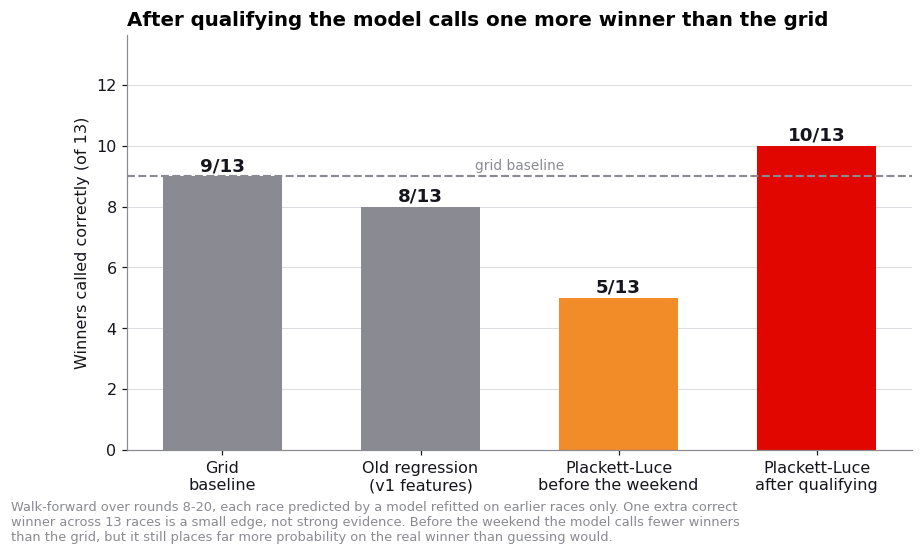

In [6]:
# ============================================================
# FIGURE 5 - RACE ORDER, WALK-FORWARD (Models 6 and 7 v2)
# Report section: Race order and points probability
# ============================================================
d = R6v2
short = ["Grid\nbaseline", "Old regression\n(v1 features)",
         "Plackett-Luce\nbefore the weekend", "Plackett-Luce\nafter qualifying"]
wins = [int(str(w).split("/")[0]) for w in d["winner"]]
total = int(str(d["winner"].iloc[0]).split("/")[1])
cols = [GREY, GREY, "#F28C28", RED]

fig, ax = plt.subplots(figsize=(9.2, 4.9))
bars = ax.bar(short, wins, color=cols, width=0.6)
ax.axhline(wins[0], color=GREY, ls="--", lw=1.4)
ax.text(1.5, wins[0] + 0.12, "grid baseline", ha="center", va="bottom", fontsize=9, color=GREY)
for b, w in zip(bars, wins):
    ax.text(b.get_x() + b.get_width() / 2, w + 0.18, f"{w}/{total}", ha="center",
            fontsize=12, fontweight="bold", color=DARK)
ax.set_ylabel(f"Winners called correctly (of {total})")
ax.set_ylim(0, total * 1.05)
ax.grid(axis="x", visible=False)
ax.set_title("After qualifying the model calls one more winner than the grid")
save(fig, "fig5_race_winners_walkforward",
     "Walk-forward over rounds 8-20, each race predicted by a model refitted on earlier races only. One extra correct\n"
     "winner across 13 races is a small edge, not strong evidence. Before the weekend the model calls fewer winners\n"
     "than the grid, but it still places far more probability on the real winner than guessing would.")
for s, w in zip(short, wins):
    CHECK.append(("Fig 5", f"{s.replace(chr(10), ' ')} winners", f"{w}/{total}"))
for lab_, col in [("MAE", "MAE"), ("podium hits", "podium"), ("rank corr", "rho")]:
    CHECK.append(("Fig 5", f"(context) {lab_} grid vs PL-post",
                  f"{d[col].iloc[0]} vs {d[col].iloc[3]}"))


# ============================================================
# FIGURE 6 - CONSISTENCY BY COMPOUND (Model 8, descriptive)
# Report section: Lap-time consistency
# ============================================================

saved: figures\fig6_consistency_by_compound.png


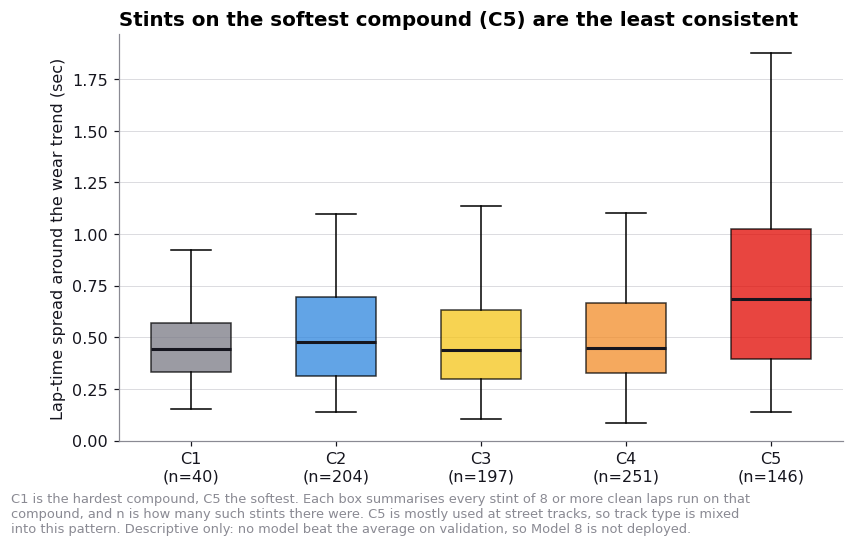

In [7]:
# ============================================================
# FIGURE 6 - CONSISTENCY BY COMPOUND (Model 8, descriptive)
# Report section: Lap-time consistency
# ============================================================
rows = []
for (rnd, drv, stint), s in pace[pace.Compound != "INTERMEDIATE"].groupby(["Round", "Driver", "Stint"]):
    if len(s) >= 8 and s["TyreLife"].nunique() >= 3:
        x, yv = s["TyreLife"].values.astype(float), s["LapTime_sec"].values
        b, a = np.polyfit(x, yv, 1)
        rows.append({"compound_C": int(s["compound_C"].iloc[0]),
                     "consistency": (yv - (b * x + a)).std(ddof=1)})
st = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
data = [st[st.compound_C == c].consistency for c in [1, 2, 3, 4, 5]]
bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                medianprops=dict(color=DARK, lw=2))
ax.set_xticks(range(1, 6))
ax.set_xticklabels([f"C{c}\n(n={len(d)})" for c, d in zip([1, 2, 3, 4, 5], data)])
for patch, c in zip(bp["boxes"], [1, 2, 3, 4, 5]):
    patch.set_facecolor(C_COLORS[c])
    patch.set_alpha(0.75)
ax.set_ylabel("Lap-time spread around the wear trend (sec)")
ax.grid(axis="x", visible=False)
ax.set_title("Stints on the softest compound (C5) are the least consistent")
save(fig, "fig6_consistency_by_compound",
     "C1 is the hardest compound, C5 the softest. Each box summarises every stint of 8 or more clean laps run on that\n"
     "compound, and n is how many such stints there were. C5 is mostly used at street tracks, so track type is mixed\n"
     "into this pattern. Descriptive only: no model beat the average on validation, so Model 8 is not deployed.")
for c, dd in zip([1, 2, 3, 4, 5], data):
    CHECK.append(("Fig 6", f"C{c} stints / median spread", f"{len(dd)} / {dd.median():.3f}s"))


# ============================================================
# AUDIT - every number that appears in a figure, printed once
# Check these against the figure captions in the report.
# ============================================================

In [8]:
print("\n" + "=" * 74)
print("NUMBERS USED IN THE FIGURES (check these against the report text)")
print("=" * 74)
cur = None
for fig_, what, val in CHECK:
    if fig_ != cur:
        print()
        cur = fig_
    print(f"  {fig_:7s} {what:46s} {val}")
print("\n" + "=" * 74)


NUMBERS USED IN THE FIGURES (check these against the report text)

  Fig 1   total race laps                                23,323
  Fig 1   rounds                                         20

  Fig 2   random split R2                                0.57
  Fig 2   time split R2                                  -0.164

  Fig 3   Never-pit baseline PR-AUC val / test           0.037 / 0.036
  Fig 3   Logistic regression PR-AUC val / test          0.088 / 0.117
  Fig 3   Gradient boosting PR-AUC val / test            0.071 / 0.136

  Fig 4   Recent-form baseline MAE / rho                 2.17 / 0.883
  Fig 4   Form only (before the weekend) MAE / rho       2.17 / 0.887
  Fig 4   Form + practice (after FP3) MAE / rho          1.75 / 0.916

  Fig 5   Grid baseline winners                          9/13
  Fig 5   Old regression (v1 features) winners           8/13
  Fig 5   Plackett-Luce before the weekend winners       5/13
  Fig 5   Plackett-Luce after qualifying winners         10/13
  Fig 